Tugas Mechine Learning 9

9.1 Persiapan Library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

9.2 Import Dataset

In [ ]:
data = load_wine(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y,
      test_size=0.2, random_state=42,stratify=y)

9.3 Preprocessing dan Training Model

In [ ]:
rf = RandomForestClassifier(n_estimators=300,
      oob_score=True,random_state=42)
rf.fit(X_train, y_train)

ada = AdaBoostClassifier(n_estimators=100, random_state=42)
ada.fit(X_train, y_train)

gb = GradientBoostingClassifier(n_estimators=100,
        learning_rate=0.1,random_state=42)
gb.fit(X_train, y_train)

tree_tunggal = DecisionTreeClassifier(random_state=42).fit(
    X_train,
    y_train)

9.4 Evaluasi

In [ ]:
print("OOB Score Random Forest:", round(rf.oob_score_, 3))

for nama,model in [("Decision Tree Tunggal",tree_tunggal),
    ("Random Forest",rf),("AdaBoost",ada),
    ("Gradient Boosting",gb)]:
    acc = accuracy_score(y_test, model.predict(X_test))
    print(f"{nama}: Akurasi Test = {acc:.3f}")

OOB Score Random Forest: 0.979
Decision Tree Tunggal: Akurasi Test = 0.944
Random Forest: Akurasi Test = 1.000
AdaBoost: Akurasi Test = 0.917
Gradient Boosting: Akurasi Test = 0.944


9.5 Visualisasi

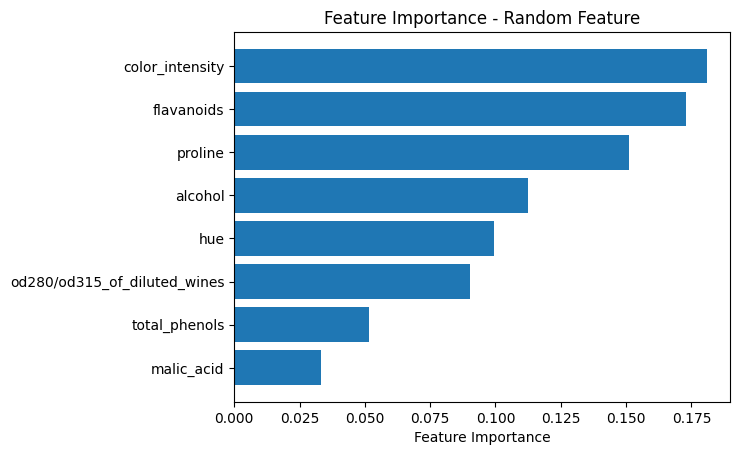

In [ ]:
importances = rf.feature_importances_
idx = np.argsort(importances)[::-1][:8]
plt.barh([data.feature_names[i] for i in idx][::-1],
         importances[idx][::-1])
plt.xlabel("Feature Importance")
plt.title("Feature Importance - Random Feature")
plt.show()

9.6 Pratikum

In [ ]:
for n in [10, 50, 100, 300, 500]:
  model = RandomForestClassifier(n_estimators=n, oob_score=True, random_state=42)
  model.fit(X_train, y_train)
  test_acc = accuracy_score(y_test, model.predict(X_test))
  print(f"n_estimators={n}: OOB={model.oob_score_:.3f}, Test Acc={test_acc:.3f}")

n_estimators=10: OOB=0.951, Test Acc=1.000
n_estimators=50: OOB=0.972, Test Acc=1.000
n_estimators=100: OOB=0.979, Test Acc=1.000
n_estimators=300: OOB=0.979, Test Acc=1.000
n_estimators=500: OOB=0.979, Test Acc=1.000


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Inisialisasi model yang akan dibandingkan
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, oob_score=True, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
}

# Menyiapkan Stratified 5-Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# List untuk menyimpan hasil
results = []

# Melakukan cross-validation untuk setiap model
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring='f1_macro')
    results.append({
        "Model": name,
        "F1-Macro Mean": round(scores.mean(), 4),
        "F1-Macro Std": round(scores.std(), 4)
    })

# Mengonversi hasil ke dalam DataFrame
df_results = pd.DataFrame(results)
display(df_results.sort_values(by="F1-Macro Mean", ascending=False))

,Model,F1-Macro Mean,F1-Macro Std
1,Random Forest,0.9840,0.0209
2,AdaBoost,0.9286,0.0436
3,Gradient Boosting,0.9237,0.0304
0,Decision Tree,0.8960,0.0361
